# Workshop 4-1: K-Means clustering

**Real-life problem:** Grouping wholesale customers into segments so account managers can treat them differently.

**My twist:** Swap the workshop's data for `wholesale_customers.csv` (440 customers, annual spend in six categories; UCI Machine Learning Repository, check the licence on its page). Scale the features, pick k with the elbow and silhouette score, then profile each cluster. Prefer music? Cluster tracks by audio features instead.

**Done when:** A cluster-profile table (mean spend per category) and a name plus a suggested action for each segment, e.g. 'high Fresh, low Grocery: restaurants, offer weekly delivery'.

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). Everything below the line starts as that baseline; edit it.*

---


## Part A: how K-Means works (the lecturer's baseline)

From-scratch assignment/update loop on 19 toy points, then the same thing with `sklearn`. Left as is.

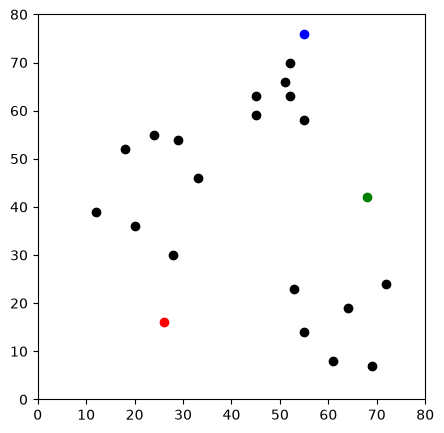

In [16]:
## Initialisation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

df = pd.DataFrame({
    'x': [12, 20, 28, 18, 29, 33, 24, 45, 45, 52, 51, 52, 55, 53, 55, 61, 64, 69, 72],
    'y': [39, 36, 30, 52, 54, 46, 55, 59, 63, 70, 66, 63, 58, 23, 14, 8, 19, 7, 24]
})


np.random.seed(200)
k = 3
# centroids[i] = [x, y]
centroids = {
    i+1: [np.random.randint(0, 80), np.random.randint(0, 80)]
    for i in range(k)
}
    
fig = plt.figure(figsize=(5, 5))
plt.scatter(df['x'], df['y'], color='k')
colmap = {1: 'r', 2: 'g', 3: 'b'}
for i in centroids.keys():
    plt.scatter(*centroids[i], color=colmap[i])
plt.xlim(0, 80)
plt.ylim(0, 80)
plt.show()


    x   y  distance_from_1  distance_from_2  distance_from_3  closest color
0  12  39        26.925824        56.080300        56.727418        1     r
1  20  36        20.880613        48.373546        53.150729        1     r
2  28  30        14.142136        41.761226        53.338541        1     r
3  18  52        36.878178        50.990195        44.102154        1     r
4  29  54        38.118237        40.804412        34.058773        3     b


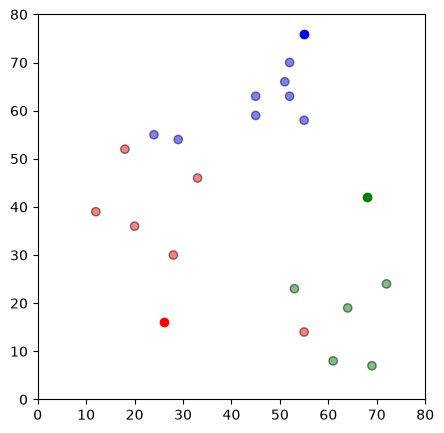

In [17]:
## Assignment Stage

def assignment(df, centroids):
    for i in centroids.keys():
        # sqrt((x1 - x2)^2 - (y1 - y2)^2)
        df['distance_from_{}'.format(i)] = (
            np.sqrt(
                (df['x'] - centroids[i][0]) ** 2
                + (df['y'] - centroids[i][1]) ** 2
            )
        )
    centroid_distance_cols = ['distance_from_{}'.format(i) for i in centroids.keys()]
    df['closest'] = df.loc[:, centroid_distance_cols].idxmin(axis=1)
    df['closest'] = df['closest'].map(lambda x: int(x.lstrip('distance_from_')))
    df['color'] = df['closest'].map(lambda x: colmap[x])
    return df

df = assignment(df, centroids)
print(df.head())

fig = plt.figure(figsize=(5, 5))
plt.scatter(df['x'], df['y'], color=df['color'], alpha=0.5, edgecolor='k')
for i in centroids.keys():
    plt.scatter(*centroids[i], color=colmap[i])
plt.xlim(0, 80)
plt.ylim(0, 80)
plt.show()

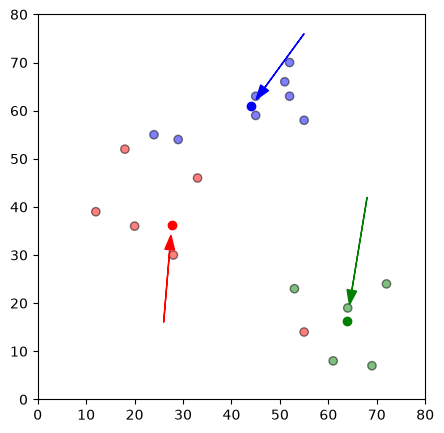

In [18]:
## Update Stage

import copy

old_centroids = copy.deepcopy(centroids)

def update(k):
    for i in centroids.keys():
        centroids[i][0] = np.mean(df[df['closest'] == i]['x'])
        centroids[i][1] = np.mean(df[df['closest'] == i]['y'])
    return k

centroids = update(centroids)
    
fig = plt.figure(figsize=(5, 5))
ax = plt.axes()
plt.scatter(df['x'], df['y'], color=df['color'], alpha=0.5, edgecolor='k')
for i in centroids.keys():
    plt.scatter(*centroids[i], color=colmap[i])
plt.xlim(0, 80)
plt.ylim(0, 80)
for i in old_centroids.keys():
    old_x = old_centroids[i][0]
    old_y = old_centroids[i][1]
    dx = (centroids[i][0] - old_centroids[i][0]) * 0.75
    dy = (centroids[i][1] - old_centroids[i][1]) * 0.75
    ax.arrow(old_x, old_y, dx, dy, head_width=2, head_length=3, fc=colmap[i], ec=colmap[i])
plt.show()

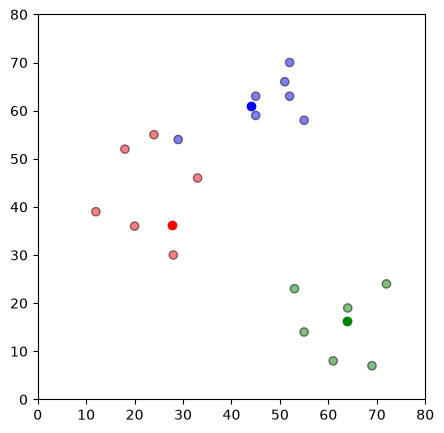

In [19]:
## Repeat Assigment Stage

df = assignment(df, centroids)

# Plot results
fig = plt.figure(figsize=(5, 5))
plt.scatter(df['x'], df['y'], color=df['color'], alpha=0.5, edgecolor='k')
for i in centroids.keys():
    plt.scatter(*centroids[i], color=colmap[i])
plt.xlim(0, 80)
plt.ylim(0, 80)
plt.show()

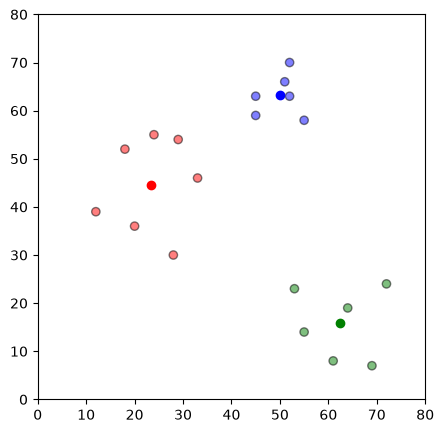

In [20]:
# Continue until all assigned categories don't change any more
while True:
    closest_centroids = df['closest'].copy(deep=True)
    centroids = update(centroids)
    df = assignment(df, centroids)
    if closest_centroids.equals(df['closest']):
        break

fig = plt.figure(figsize=(5, 5))
plt.scatter(df['x'], df['y'], color=df['color'], alpha=0.5, edgecolor='k')
for i in centroids.keys():
    plt.scatter(*centroids[i], color=colmap[i])
plt.xlim(0, 80)
plt.ylim(0, 80)
plt.show()

In [21]:
df = pd.DataFrame({
    'x': [12, 20, 28, 18, 29, 33, 24, 45, 45, 52, 51, 52, 55, 53, 55, 61, 64, 69, 72],
    'y': [39, 36, 30, 52, 54, 46, 55, 59, 63, 70, 66, 63, 58, 23, 14, 8, 19, 7, 24]
})

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3)
kmeans.fit(df)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)",

In [22]:
labels = kmeans.predict(df)
centroids = kmeans.cluster_centers_

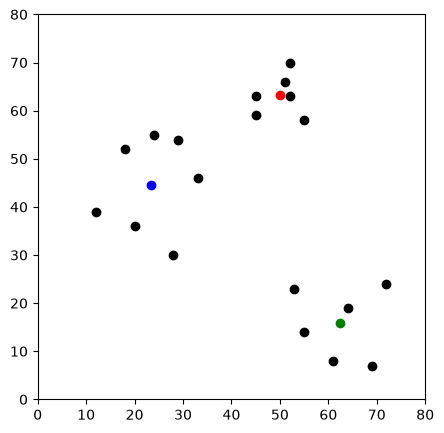

In [23]:
fig = plt.figure(figsize=(5, 5))
colmap = {1: 'r', 2: 'g', 3: 'b'}
plt.scatter(df['x'], df['y'], color='k')
for idx, centroid in enumerate(centroids):
    plt.scatter(*centroid, color=colmap[idx+1])
plt.xlim(0, 80)
plt.ylim(0, 80)
plt.show()

---
## Part B: real life: segmenting wholesale customers

**Data:** UCI *Wholesale customers*: 440 clients of a wholesale distributor, with annual spend (in monetary units) on six product categories. `Channel` (1 = Horeca: hotels/restaurants/cafés, 2 = Retail) and `Region` are also included.

**Question:** which *kinds* of customer do we have, and how should an account manager treat each?

**Plan:** look at the data → fix the scale problem → choose k → profile the segments → decide what we'd do for each.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

customers = pd.read_csv('wholesale_customers.csv')
spend_cols = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

print(customers.shape, '| missing values:', customers.isna().sum().sum())
customers[spend_cols].describe().round(0)

(440, 8) | missing values: 0


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


Fresh                2.6
Milk                 4.1
Grocery              3.6
Frozen               5.9
Detergents_Paper     3.6
Delicassen          11.2
dtype: float64


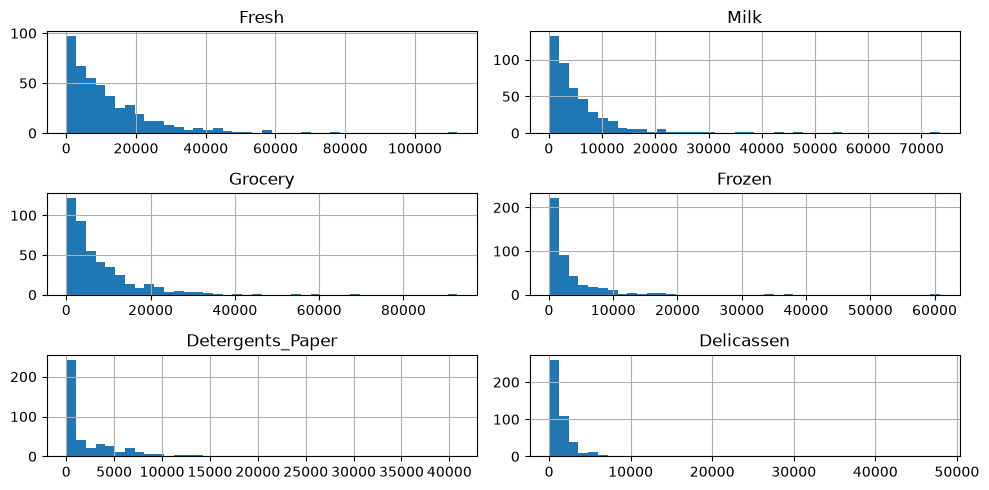

In [25]:
# K-Means works on distances, so a few huge spenders can dominate. How skewed is spend?
print(customers[spend_cols].skew().round(1))   # 0 = symmetric; above ~1 = long right tail

customers[spend_cols].hist(bins=40, figsize=(10, 5))
plt.tight_layout()
plt.show()

Every category has a long right tail (skew 2.6 to 11). A handful of customers spend 10-50x the typical amount.

Does that matter? Compare clustering on **raw** spend (just standardised) with **log-transformed** spend (log first, then standardised), using k=3 for both.

In [26]:
X_raw = StandardScaler().fit_transform(customers[spend_cols])
X_log = StandardScaler().fit_transform(np.log1p(customers[spend_cols]))   # log first, then scale

for name, X in [('raw + scaled', X_raw), ('log + scaled', X_log)]:
    km_test = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
    sizes = sorted(np.bincount(km_test.labels_).tolist(), reverse=True)
    print(f'{name:13s} silhouette = {silhouette_score(X, km_test.labels_):.2f}   customers per cluster = {sizes}')

raw + scaled  silhouette = 0.55   customers per cluster = [393, 45, 2]
log + scaled  silhouette = 0.26   customers per cluster = [213, 147, 80]


**Don't trust the higher score.** On raw spend the silhouette looks much better (about 0.55 vs 0.26), but the clusters are roughly 393 / 45 / 2 customers: the algorithm has just carved off a few outliers and lumped everyone else together. That is no use to an account manager.

The log-transformed version scores lower but gives balanced groups, so we continue with it. (Lesson: a metric tells you how well the algorithm did *its* job, not whether the result is useful.)

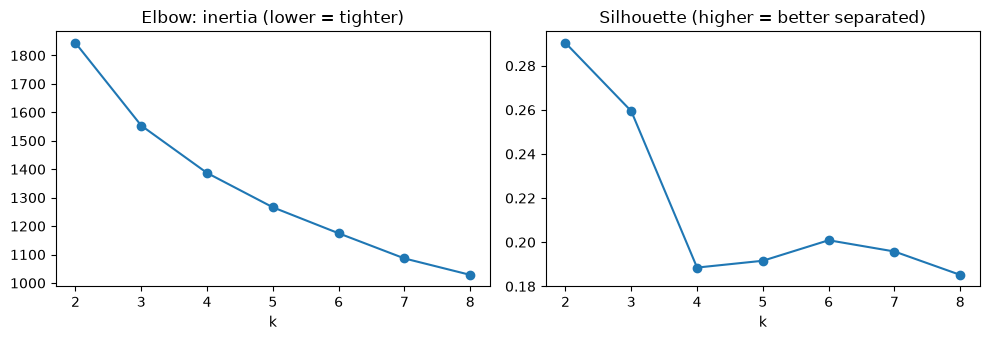

In [27]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_log)
    inertia.append(km_k.inertia_)
    sil.append(silhouette_score(X_log, km_k.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow: inertia (lower = tighter)'); ax[0].set_xlabel('k')
ax[1].plot(ks, sil, 'o-'); ax[1].set_title('Silhouette (higher = better separated)'); ax[1].set_xlabel('k')
plt.tight_layout()
plt.show()

**Choosing k.** There is no sharp elbow, and silhouette is highest at k=2. But k=2 only splits Horeca from Retail, which the `Channel` column already tells us, so it gives an account manager nothing new.

I choose **k = 4**: four segments of 14-30% of customers each, with clearly different buying patterns. The cost is a low silhouette (about 0.19): the segments overlap, so customers are a continuum and the segments are guidance, not hard boxes. Change `K` below and re-run to see how the story changes.

In [28]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_log)

# number the segments by average total spend (0 = smallest buyers) so labels are stable between runs
total_spend = customers[spend_cols].sum(axis=1)
order = total_spend.groupby(km.labels_).mean().sort_values().index
customers['segment'] = pd.Series(km.labels_).map({old: new for new, old in enumerate(order)})

customers['segment'].value_counts().sort_index()

segment
0    132
1     61
2    129
3    118
Name: count, dtype: int64

In [29]:
# segment profile: size, typical spend per category (original units, not log), money share, channel mix
profile = customers.groupby('segment')[spend_cols].mean().round(0).astype(int)
profile.insert(0, 'customers', customers['segment'].value_counts().sort_index())
profile['share_of_spend_%'] = (customers.groupby('segment')[spend_cols].sum().sum(axis=1)
                               / customers[spend_cols].sum().sum() * 100).round(0).astype(int)
profile['horeca_%'] = (customers.groupby('segment')['Channel'].apply(lambda s: (s == 1).mean()) * 100).round(0).astype(int)
profile

,customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,share_of_spend_%,horeca_%
segment,,,,,,,,,
0,132,9633,1570,2072,2175,345,585,15,99
1,61,2809,7062,12349,566,5343,636,12,34
2,129,19374,4068,4445,6184,723,2323,33,95
3,118,11339,11759,16088,1968,6806,2164,40,20


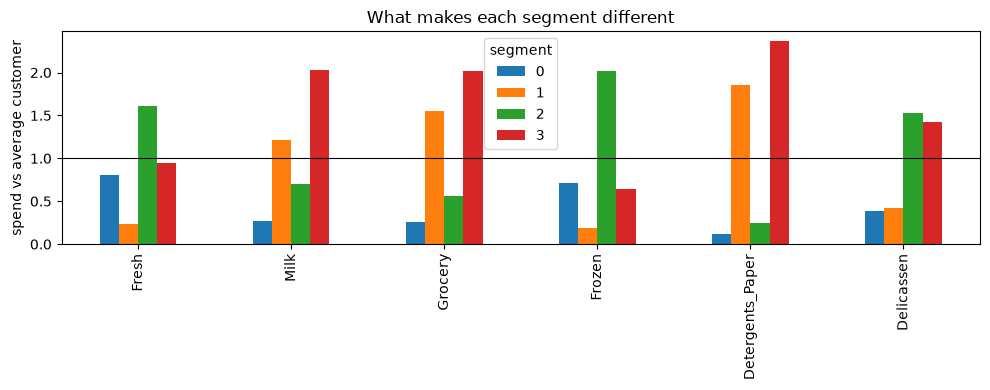

In [30]:
# what makes each segment different: spend relative to the average customer (1.0 = average)
relative = customers.groupby('segment')[spend_cols].mean() / customers[spend_cols].mean()

relative.T.plot(kind='bar', figsize=(10, 4))
plt.axhline(1, color='k', lw=0.8)
plt.ylabel('spend vs average customer')
plt.title('What makes each segment different')
plt.legend(title='segment')
plt.tight_layout()
plt.show()

### Segments and what we'd do

| Segment | Name | Customers | Share of spend | Who they are | What we do |
|---|---|---|---|---|---|
| 3 | **Big grocery retailers** | 118 (27%) | 40% | Highest spenders; heavy on milk, grocery and detergents; mostly Retail | Protect and grow: a named account manager, volume pricing, and an early-warning check for customers whose orders drop. |
| 2 | **Fresh-led restaurants and cafés** | 129 (29%) | 33% | Nearly all Horeca; heavy on fresh and frozen, light on everything else | Protect: frequent fresh-delivery slots and a reliable cut-off time (freshness is what they judge us on); offer a frozen add-on. |
| 0 | **Small food-service accounts** | 132 (30%) | 15% | Almost all Horeca; low spend in every category | Serve cheaply: self-serve reordering and a monthly promotions email, with no dedicated account manager. |
| 1 | **Dry-goods and household stores** | 61 (14%) | 12% | A mix of Retail and Horeca; grocery, milk and cleaning products, very little fresh or frozen | Maintain: bundle grocery and detergent lines and use ambient (non-chilled) delivery slots, which are cheap to run. |

*(Segments are listed by share of spend, not by number. Counts and spend shares come from the profile table above.)*

**The headline:** segments 2 and 3 are 56% of customers but about 73% of spend (33% + 40%, from the table above with K = 4), so that is where account-manager time pays off.

**What I'd check next:** are segments 1 and 3 really different or just 'small' and 'big' versions of the same shop? (Try K = 3 and compare.) And would a different `Region` mix change the plan?